# Phase 11.2: SVM with an RBF kernel

**Owner:** Rotana · **Model:** `SVC` · **Writes to:** `data/processed/11_2_svm/`

**What it means:** An SVM finds the boundary with the widest gap between classes. The RBF kernel lets that boundary curve around groups of squares, which a straight line can't do.

**Key idea:** It can fit curved boundaries that softmax can't. The price is time, so the grid runs on a 10,000-square sample and only the winner is fitted on all of train.

Full step-by-step guide and the results sheet: [team plan](https://claude.ai/artifact/Rst8GHxAbeHavg4JS2RZV3) (tab 11.2).

### What we agreed on (same for all three notebooks)
- Train on the **46,408 balanced training squares**, score on the **36,000 validation squares**. The test set is not loaded.
- Pipeline: `StandardScaler` → `PCA(60, random_state=42)` → model.
- Tuning: `GridSearchCV` on train only, `GroupKFold(5)` grouped by photo, `scoring="f1_macro"`.
- Main metric: validation **macro F1** (floor to beat: **0.187**, always answering "none"). Second: **pothole (D40) recall**.

### What to tune

| Setting | Values to try | What it controls |
|---|---|---|
| `C` | 0.1, 1, 10, 100 | How hard it tries to get every training square right. |
| `gamma` | "scale", 0.01, 0.001 | How far one square's influence reaches. Large gamma gives wiggly boundaries. |

**Fixed:** `kernel="rbf"`, `class_weight="balanced"`; `probability=True` only on the final fit.

## 1. Setup

Everything shared lives in `ml/training.py`, so this notebook only adds the model:
- `load_data()`: the agreed rows (46,408 balanced training squares, 36,000 validation squares);
- `make_pipeline(clf)`: `StandardScaler` → `PCA(60)` → your model;
- `CV`: `GroupKFold(5)`, folds split by photo;
- `search_table(gs, OUT)`: saves the grid search to `cv_results.csv` and returns the best row;
- `report(...)`: the same evaluation for every model; writes `results.json` and `confusion_matrix.png`.

Don't change `ml/training.py` on your own: a change there changes all three results.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config
from ml.training import CV, load_data, make_pipeline, output_dir, report, search_table

SEED = config.SEED
OUT = output_dir("11_2_svm")     # this notebook writes only here

data = load_data()                # balanced train + validation; the test set is never loaded
X_tr, y_tr, groups_tr, X_va, y_va = data
print("train", X_tr.shape, "| val", X_va.shape)

train (46408, 1769) | val (36000, 1769)


## 2. Baseline: is it working at all? (Phase 10)

Fit the model once with default settings and score it on validation.

**Check:** clearly above 0.187.

In [2]:
from sklearn.svm import SVC

rng = np.random.default_rng(SEED)
s = rng.choice(len(X_tr), size=10_000, replace=False)   # the tuning sample, reused in step 3
print("tuning sample:", len(s), "squares from", len(np.unique(groups_tr[s])), "photos | per class",
      dict(zip(config.CLASSES, np.bincount(y_tr[s]))))

t = time.perf_counter()
base = make_pipeline(SVC(kernel="rbf", class_weight="balanced"))
base.fit(X_tr[s], y_tr[s])
base_fit = time.perf_counter() - t
t = time.perf_counter()
base_f1 = f1_score(y_va, base.predict(X_va), average="macro")
base_pred = time.perf_counter() - t

# what gamma="scale" works out to here: 1 / (n_features * variance of the PCA output)
Z = base[:-1].transform(X_tr[s])
gamma_scale = 1 / (Z.shape[1] * Z.var())

print(f"fit {base_fit:.0f} s | predict 36,000 val squares {base_pred:.0f} s "
      f"| {base[-1].n_support_.sum():,} support vectors | gamma='scale' = {gamma_scale:.5f}")
print(f"baseline val macro F1 {base_f1:.4f} | floor 0.187")
assert base_f1 > 0.187, "the baseline does not beat always answering 'none': check data and pipeline first"


tuning sample: 10000 squares from 3629 photos | per class {'D00': np.int64(707), 'D10': np.int64(396), 'D20': np.int64(2781), 'D40': np.int64(449), 'none': np.int64(5667)}


fit 20 s | predict 36,000 val squares 40 s | 8,639 support vectors | gamma='scale' = 0.00111
baseline val macro F1 0.2340 | floor 0.187


## 3. Grid search, on train only

Try every combination in the table above with `GridSearchCV(..., cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True)` and `groups=groups_tr`.

**Check:** one row per combination in `gs.cv_results_`; note how long it took.

In [3]:
pipe = make_pipeline(SVC(kernel="rbf", class_weight="balanced"))
grid = {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.001]}

gs = GridSearchCV(pipe, grid, cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True,
                  refit=False)   # the winner is fitted on the full train set in step 5
t = time.perf_counter()
gs.fit(X_tr[s], y_tr[s], groups=groups_tr[s])
grid_secs = time.perf_counter() - t

n_settings = len(gs.cv_results_["params"])
print(f"{n_settings} settings x {CV.get_n_splits()} folds = {n_settings * CV.get_n_splits()} fits "
      f"in {grid_secs / 60:.1f} min")


12 settings x 5 folds = 60 fits in 9.0 min


## 4. Read the search

`cv, best = search_table(gs, OUT)` saves the search and returns the best row. Plot the mean macro F1 per setting.

**Check:** if the best value is at the edge of the grid, add one value beyond it once and note it.

best on the grid: {'clf__C': 10, 'clf__gamma': 'scale'} | CV macro F1 0.3274 ± 0.0158


best was on the edge; tried [{'clf__C': 10, 'clf__gamma': 0.0001}]: the grid's best still wins
BEST: {'clf__C': 10, 'clf__gamma': 'scale'} | CV macro F1 0.3274 ± 0.0158


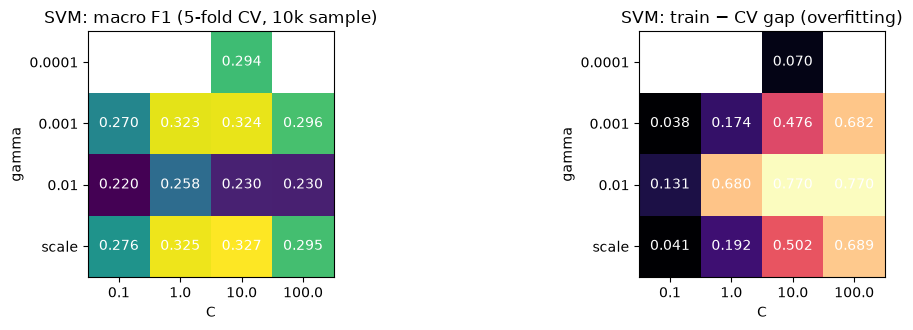

,C,gamma,mean_test_score,std_test_score,mean_train_score,gap,mean_fit_time
0,10.0,scale,0.3274,0.0158,0.8289,0.5015,18.1719
1,1.0,scale,0.3245,0.0092,0.5166,0.1921,25.6252
2,10.0,0.001,0.3239,0.0141,0.7998,0.4759,22.0983
3,1.0,0.001,0.3229,0.0067,0.4969,0.1741,22.3026
4,100.0,0.001,0.2962,0.0114,0.9780,0.6818,39.1656
5,100.0,scale,0.2954,0.0099,0.9844,0.6890,29.4060
6,10.0,0.0001,0.2942,0.0119,0.3641,0.0698,110.6910
7,0.1,scale,0.2755,0.0137,0.3166,0.0411,51.2658
8,0.1,0.001,0.2695,0.0119,0.3080,0.0385,31.1175
9,1.0,0.01,0.2581,0.0084,0.9383,0.6802,32.6623


In [4]:
cv, best = search_table(gs, OUT)          # saves cv_results.csv, returns the best row
print("best on the grid:", best["params"], f"| CV macro F1 {best['mean_test_score']:.4f} "
      f"± {best['std_test_score']:.4f}")

# Edge check: if the best C or gamma is the largest/smallest value tried, try one value beyond it once.
C_b, g_b = best["params"]["clf__C"], best["params"]["clf__gamma"]
g_num = gamma_scale if g_b == "scale" else g_b   # "scale" is a number in disguise (see step 2)
beyond = []
if C_b == max(grid["clf__C"]):
    beyond.append({"clf__C": [C_b * 10], "clf__gamma": [g_b]})
elif C_b == min(grid["clf__C"]):
    beyond.append({"clf__C": [C_b / 10], "clf__gamma": [g_b]})
if g_num >= 0.01:
    beyond.append({"clf__C": [C_b], "clf__gamma": [0.1]})
elif g_num <= 0.001 * 1.5:
    beyond.append({"clf__C": [C_b], "clf__gamma": [0.0001]})

edge_note = "best is inside the grid: no extra values needed"
if beyond:
    gs2 = GridSearchCV(pipe, beyond, cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True,
                       refit=False)
    t = time.perf_counter()
    gs2.fit(X_tr[s], y_tr[s], groups=groups_tr[s])
    grid_secs += time.perf_counter() - t
    extra = pd.DataFrame(gs2.cv_results_).assign(extra=True)
    cv = pd.concat([cv.assign(extra=False), extra], ignore_index=True)
    cv["rank_test_score"] = cv["mean_test_score"].rank(ascending=False, method="min").astype(int)
    cv.to_csv(OUT / "cv_results.csv", index=False)
    new_best = cv.loc[cv["mean_test_score"].idxmax()]
    edge_note = (f"best was on the edge; tried {[p for p in gs2.cv_results_['params']]}: "
                 + ("a value beyond the grid won" if new_best["extra"] else "the grid's best still wins"))
    best = new_best
print(edge_note)
print("BEST:", best["params"], f"| CV macro F1 {best['mean_test_score']:.4f} ± {best['std_test_score']:.4f}")

cv["C"] = cv["param_clf__C"].astype(float)
cv["gamma"] = cv["param_clf__gamma"].astype(str)
cv["gap"] = cv["mean_train_score"] - cv["mean_test_score"]
heat = cv.pivot_table(index="gamma", columns="C", values="mean_test_score")
gap = cv.pivot_table(index="gamma", columns="C", values="gap")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, table, title, cmap in [(axes[0], heat, "macro F1 (5-fold CV, 10k sample)", "viridis"),
                               (axes[1], gap, "train − CV gap (overfitting)", "magma")]:
    ax.imshow(table, cmap=cmap)
    ax.set(xticks=range(table.shape[1]), xticklabels=table.columns, yticks=range(table.shape[0]),
           yticklabels=table.index, xlabel="C", ylabel="gamma", title=f"SVM: {title}")
    for (i, j), v in np.ndenumerate(table.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white")
fig.tight_layout()
fig.savefig(OUT / "grid_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

cols = ["C", "gamma", "mean_test_score", "std_test_score", "mean_train_score", "gap", "mean_fit_time"]
cv.sort_values("mean_test_score", ascending=False)[cols].round(4).reset_index(drop=True)


## 5. Final model, scored on validation

`report(pipe, data, OUT, "11.2 SVM", best, train_seconds)` writes `results.json` and `confusion_matrix.png`.

**Check:** read the D40 row of the confusion matrix: where do the missed potholes go?

final fit on 46,408 squares: 78.2 min | 37,004 support vectors


                          precision    recall  f1-score   support

D00 · Longitudinal crack      0.052     0.269     0.088       743
  D10 · Transverse crack      0.048     0.313     0.083       323
   D20 · Alligator crack      0.185     0.495     0.269      2915
           D40 · Pothole      0.054     0.259     0.090       413
        none · No damage      0.966     0.621     0.756     31606

                accuracy                          0.596     36000
               macro avg      0.261     0.391     0.257     36000
            weighted avg      0.865     0.596     0.689     36000

val macro F1 0.2571 | train macro F1 0.7052 | floor 0.187


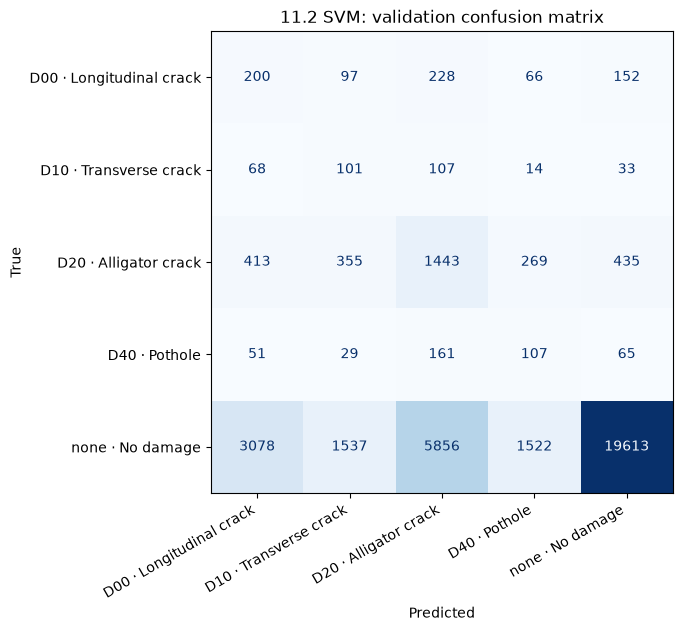

D40: 413 potholes in validation, 107 found (recall 0.259); the missed ones were called: {'D20': 161, 'none': 65, 'D00': 51, 'D10': 29}


In [5]:
params = dict(best["params"])

final = make_pipeline(SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))
final.set_params(**params)
t = time.perf_counter()
final.fit(X_tr, y_tr)                 # all 46,408 training squares
secs = time.perf_counter() - t
print(f"final fit on {len(X_tr):,} squares: {secs / 60:.1f} min "
      f"| {final[-1].n_support_.sum():,} support vectors")

t = time.perf_counter()
res = report(final, data, OUT, "11.2 SVM", best, secs)
report_secs = time.perf_counter() - t
plt.show()

# Where do the missed potholes go? (D40 row of the confusion matrix)
cm = np.array(res["confusion_matrix"])
d40 = pd.Series(cm[config.CLASS_TO_ID["D40"]], index=config.CLASSES)
print(f"D40: {d40.sum()} potholes in validation, {d40['D40']} found "
      f"(recall {res['per_class']['D40']['recall']:.3f}); the missed ones were called:",
      d40.drop("D40").sort_values(ascending=False).to_dict())


## 6. Check the gap and the time

Compare train and validation macro F1, and write down how long the full fit took.

In [6]:
import json

gap_final = res["train_macro_f1"] - res["val_macro_f1"]
if gap_final > 0.15:
    verdict = "overfitting: train is much better than validation"
elif res["train_macro_f1"] < 0.5:
    verdict = "underfitting: both train and validation are low"
else:
    verdict = "no clear over- or underfitting (gap within 0.15)"

summary = pd.DataFrame({
    "macro F1": [res["train_macro_f1"], best["mean_test_score"], res["val_macro_f1"]],
}, index=["train (46,408)", "CV mean (10k sample)", "validation (36,000)"]).round(4)
print(summary.to_string())
print(f"\ntrain − val gap {gap_final:.3f} -> {verdict}")

timing = pd.Series({"baseline fit (10k)": base_fit, "grid search": grid_secs,
                    "final fit (46k, probability=True)": secs,
                    "predict train + val (report)": report_secs}).div(60).round(1)
print("\nminutes:\n" + timing.to_string())

# extra numbers for the progress page (local, not committed)
(OUT / "run_log.json").write_text(json.dumps({
    "sample_size": int(len(s)), "baseline_val_macro_f1": round(float(base_f1), 4),
    "baseline_fit_s": round(base_fit, 1), "baseline_support_vectors": int(base[-1].n_support_.sum()),
    "gamma_scale_value": round(float(gamma_scale), 6), "grid_s": round(grid_secs, 1), "edge_note": edge_note,
    "final_fit_s": round(secs, 1), "report_s": round(report_secs, 1),
    "final_support_vectors": int(final[-1].n_support_.sum()),
    "support_vectors_per_class": dict(zip(config.CLASSES, map(int, final[-1].n_support_))),
    "gap": round(gap_final, 4), "verdict": verdict,
}, indent=2))


                      macro F1
train (46,408)          0.7052
CV mean (10k sample)    0.3274
validation (36,000)     0.2571

train − val gap 0.448 -> overfitting: train is much better than validation

minutes:
baseline fit (10k)                    0.3
grid search                          11.3
final fit (46k, probability=True)    78.2
predict train + val (report)          5.8


575

## 7. Diagnose before changing anything (Phase 12)

Train − validation gap above 0.15: overfitting. Both low and close: underfitting. Change **one** thing at a time, keep it only if validation macro F1 goes up, and log every try (also the failed ones).

## 8. Save and hand in

`joblib.dump(...)` the final pipeline to `OUT / "best_pipeline.joblib"`. Then import `results.json` in the Results sheet tab of the team plan, add your observations and download the PDF.

In [7]:
import joblib

joblib.dump(final, OUT / "best_pipeline.joblib")
for f in sorted(OUT.iterdir()):
    print(f"{f.name:24s} {f.stat().st_size / 1e6:8.2f} MB")


best_pipeline.joblib        20.76 MB
confusion_matrix.png         0.07 MB
cv_results.csv               0.01 MB
grid_heatmap.png             0.07 MB
results.json                 0.00 MB
run_log.json                 0.00 MB
tools                        0.00 MB
